<a href="https://colab.research.google.com/github/bsheese/cs377/blob/main/18_classification/18_6_Ensemble/18_6_2_Bagging_and_Random_Forests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagging and Random Forests

---

## Introduction

In the previous notebook, we saw that a single decision tree is prone to overfitting. Small changes in the training data can produce very different tree structures. Even with careful depth tuning, a single tree's performance is limited.

In this notebook, we address this instability using **ensemble methods**. The core idea is similar to the "wisdom of crowds": averaging the predictions of many different trees usually produces a model that is more stable and more accurate than any single tree.

Recall from 17_2_2: Random Forests reduce **variance** by averaging many deep, uncorrelated trees. Bagging does the same but without the feature randomness that decorrelates the trees.

### Learning Objectives
By the end of this notebook, you will be able to:
1. Implement bagging to reduce model variance.
2. Calculate and interpret Out-of-Bag (OOB) error.
3. Apply the Random Forest algorithm to decorrelate individual trees.
4. See how `class_weight='balanced'` affects the precision-recall tradeoff.
5. Tune hyperparameters using GridSearchCV.
6. Analyze feature importance and understand its limitations with correlated features.
7. Compare the stability of single trees vs. ensembles using k-fold cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc
)

sns.set_context("talk")
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

# Flip target: 1=malignant, 0=benign (matching original UCI encoding)
y = 1 - y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Class distribution after flip: {y_test.mean():.1%} malignant (1), {(1-y_test.mean()):.1%} benign (0)")

Class distribution after flip: 37.4% malignant (1), 62.6% benign (0)


---
## 1. Bagging: Reducing Instability

Bagging (bootstrap aggregating) reduces the variance of high-variance estimators like decision trees.

### How It Works
1. **Bootstrap sampling**: Create many random subsets by sampling *with replacement*. Each subset is the same size as the original, but some samples appear multiple times and others not at all.
2. **Model building**: Train a separate, deep decision tree on each bootstrap sample.
3. **Aggregation**: Take a majority vote of all trees for the final prediction.

### Why It Works
Each tree overfits to its specific bootstrap sample, but the errors are different across trees. When the trees' predictions are averaged, many of these individual errors cancel out, while the patterns that most trees share remain.

### Why Deep Trees?
Notice we use `DecisionTreeClassifier()` with no depth limit, so each tree is grown deep. This might seem counterintuitive given what we learned about overfitting in 18_6_1. But bagging works *because* each tree overfits differently. If we used shallow trees, each one would be too weak on its own, and averaging weak trees doesn't help much. Deep trees fit the data well individually, and averaging them cancels out much of their individual overfitting.

In [3]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    oob_score=True,
    random_state=42
)
bag.fit(X_train, y_train)

y_pred_bag = bag.predict(X_test)
y_proba_bag = bag.predict_proba(X_test)[:, 1]

print(f"Bagging Accuracy (Test): {accuracy_score(y_test, y_pred_bag):.3f}")
print(f"Out-of-Bag (OOB) Score:  {bag.oob_score_:.3f}")

Bagging Accuracy (Test): 0.965
Out-of-Bag (OOB) Score:  0.960


### Understanding Out-of-Bag (OOB) Error

Because bootstrap sampling leaves out about 1/3 of the data for each tree, those "out-of-bag" samples serve as a built-in validation set. Each training sample is predicted using only the trees that did not see it during training, and the OOB score is the accuracy of those predictions across all training samples.

The OOB score (0.960) is very close to the test accuracy (0.965). This suggests that OOB is a reliable estimate of generalization performance, so with bagging you don't always need a separate validation set.

However, OOB is only available for bagging-based methods. For boosting and other sequential methods, you still need cross-validation.

### Handling Class Imbalance: The class_weight Parameter

Our dataset is 63% benign / 37% malignant. In a medical context, missing a cancer (false negative) is typically more costly than an unnecessary biopsy (false positive). Let's see what happens when we use `class_weight='balanced'`.

In [4]:
# Compare default vs. balanced class weights
rf_default = RandomForestClassifier(n_estimators=200, random_state=42)
rf_balanced = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)

for name, model in [("Default weights", rf_default), ("Balanced weights", rf_balanced)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n{name}:")
    print(f"  Accuracy: {accuracy_score(y_test, pred):.3f}")
    print(f"  Malignant Recall: {recall_score(y_test, pred):.3f}")
    print(f"  Missed cancers (FN): {fn}  |  Unnecessary biopsies (FP): {fp}")


Default weights:
  Accuracy: 0.971
  Malignant Recall: 0.922
  Missed cancers (FN): 5  |  Unnecessary biopsies (FP): 0



Balanced weights:
  Accuracy: 0.971
  Malignant Recall: 0.922
  Missed cancers (FN): 5  |  Unnecessary biopsies (FP): 0


On this dataset, the two models produce *identical* results, so the balanced weights changed nothing. That tells us something about the data: the breast-cancer classes are separable enough, and the 63/37 imbalance mild enough, that re-weighting does not move the decision boundary for any test sample. On harder or more severely imbalanced problems, `class_weight='balanced'` typically catches more cancers (higher recall, fewer false negatives) at the cost of more false positives (unnecessary biopsies). Whether that trade-off is worthwhile depends on the clinical context. In either case, it is worth checking what the re-weighting actually did, as we just did, rather than assuming it helped.

---
## 2. Random Forests: Decorrelating the Trees

Bagging has a weakness: the trees can be **correlated**. If one feature (e.g., `mean concave points`) dominates, every tree uses it as the top split. The trees become similar, and averaging similar trees doesn't reduce variance as much.

### How Random Forests Address This
At *each split* of *each tree*, the algorithm considers only a random subset of features (typically √p). This forces trees to explore alternative paths, decorrelating them and making the ensemble more robust.

Recall from 17_2_2: this is the same `max_features='sqrt'` parameter we saw there.

In [5]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print(f"Random Forest Accuracy (Test): {accuracy_score(y_test, y_pred_rf):.3f}")
print(f"Random Forest OOB Score:       {rf.oob_score_:.3f}")
print(f"Random Forest Malignant Recall: {recall_score(y_test, y_pred_rf):.3f}")

Random Forest Accuracy (Test): 0.971
Random Forest OOB Score:       0.952
Random Forest Malignant Recall: 0.922


---
## 3. Classification Metrics: Beyond Accuracy

In a medical diagnosis context, we need more than accuracy. Let's evaluate the Random Forest using the full metric suite from 18_1_1 and 18_1_2.

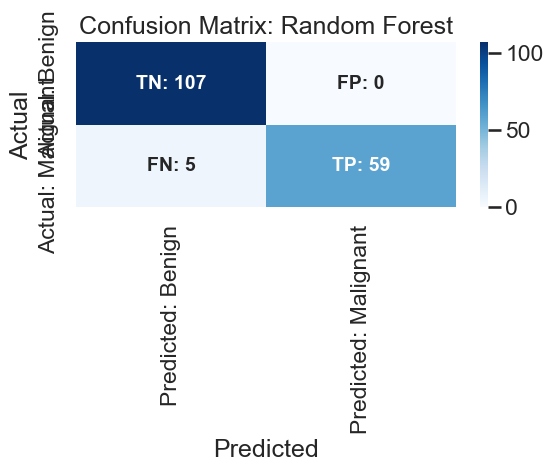


--- Medical Interpretation ---
False Negatives (missed cancers): 5
False Positives (unnecessary biopsies): 0

--- Classification Report ---
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98       107
Malignant (1)       1.00      0.92      0.96        64

     accuracy                           0.97       171
    macro avg       0.98      0.96      0.97       171
 weighted avg       0.97      0.97      0.97       171



In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm.ravel()

labels = np.array([[f'TN: {tn}', f'FP: {fp}'], [f'FN: {fn}', f'TP: {tp}']])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues',
            annot_kws={'fontsize': 14, 'fontweight': 'bold'},
            xticklabels=['Predicted: Benign', 'Predicted: Malignant'],
            yticklabels=['Actual: Benign', 'Actual: Malignant'], ax=ax)
ax.set(xlabel='Predicted', ylabel='Actual', title='Confusion Matrix: Random Forest')
plt.tight_layout()
plt.show()

print(f"\n--- Medical Interpretation ---")
print(f"False Negatives (missed cancers): {fn}")
print(f"False Positives (unnecessary biopsies): {fp}")
print(f"\n--- Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=['Benign (0)', 'Malignant (1)']))

### ROC Curve

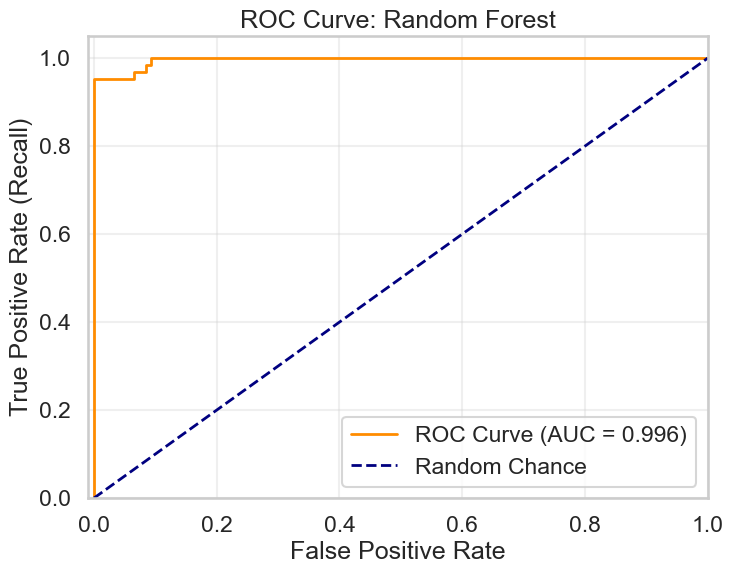

In [7]:
fpr, tpr, _ = roc_curve(y_test, y_proba_rf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr, y=tpr, estimator=None, sort=False, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve: Random Forest')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

---
## 4. Hyperparameter Tuning with GridSearchCV

So far we've used default hyperparameters. Let's systematically tune the Random Forest using GridSearchCV, just as we did in 17_2_1_4 and 18_1_6.

**Runtime note:** This cell tests 36 hyperparameter combinations across 5 folds (180 model fits). It may take 10-30 seconds.

In [8]:
param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7, None],
    'max_features': ['sqrt', 'log2', 0.5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV F1 Score: {grid_search.best_score_:.4f}")

best_rf = grid_search.best_estimator_
tuned_acc = accuracy_score(y_test, best_rf.predict(X_test))
tuned_recall = recall_score(y_test, best_rf.predict(X_test))
print(f"\nTuned RF Test Accuracy: {tuned_acc:.3f}")
print(f"Tuned RF Malignant Recall: {tuned_recall:.3f}")

# Compare with default
default_rf = RandomForestClassifier(n_estimators=500, random_state=42)
default_rf.fit(X_train, y_train)
default_acc = accuracy_score(y_test, default_rf.predict(X_test))
default_recall = recall_score(y_test, default_rf.predict(X_test))
print(f"\nDefault RF (500 trees) Accuracy: {default_acc:.3f}")
print(f"Default RF (500 trees) Recall:   {default_recall:.3f}")
print(f"\nNote: The tuned model uses only {grid_search.best_params_['n_estimators']} trees.")
print(f"More trees doesn't always mean better, but it isn't free: the simpler model")
print(f"trades a bit of malignant recall ({default_recall:.3f} -> {tuned_recall:.3f}) for far less compute.")

Best Parameters: {'max_depth': 7, 'max_features': 'log2', 'n_estimators': 100}
Best CV F1 Score: 0.9384

Tuned RF Test Accuracy: 0.965
Tuned RF Malignant Recall: 0.906



Default RF (500 trees) Accuracy: 0.971
Default RF (500 trees) Recall:   0.922

Note: The tuned model uses only 100 trees.
More trees doesn't always mean better, but it isn't free: the simpler model
trades a bit of malignant recall (0.922 -> 0.906) for far less compute.


---
## 5. Feature Importance and Its Limitations

Before looking at importance, notice that the tuned forest did slightly *worse* on the test set than the default forest: one more missed cancer (recall 0.906 versus 0.922) and accuracy 0.965 versus 0.971. With only 64 malignant tumours in the test set, a difference of one tumour is within the noise, and the grid search chose its settings by cross-validated F1 on the training data, not by test recall, so there was no guarantee it would win here.

Random Forests provide feature importance scores based on total impurity reduction across all trees. But recall from 17_2_2: **correlated features share importance**. If two features are highly correlated, a tree can split on either one, so the credit gets divided between them, or goes mostly to whichever one happens to be chosen.

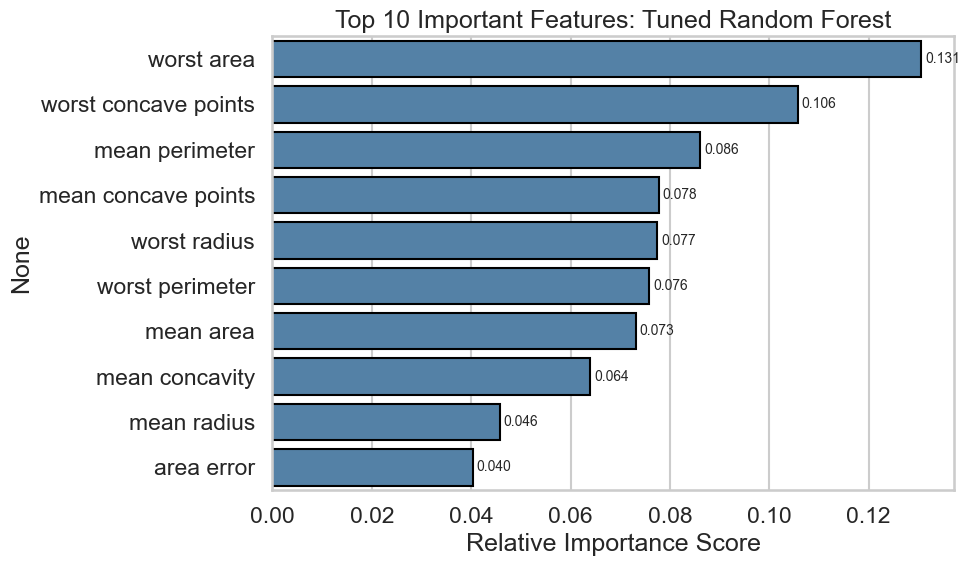

In [9]:
importances = pd.Series(best_rf.feature_importances_, index=data.feature_names)
top_10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_10.values, y=top_10.index, color='steelblue', edgecolor='black')
ax.bar_label(ax.containers[0], fmt='%.3f', padding=3, fontsize=10)
plt.xlabel('Relative Importance Score')
plt.title('Top 10 Important Features: Tuned Random Forest')

plt.tight_layout()
plt.show()

### The Correlated Features Problem

Notice two groups of closely related features in the top 10. Six of them measure the *size* of the cell nuclei: `worst area`, `mean perimeter`, `worst radius`, `worst perimeter`, `mean area` and `mean radius`. Radius, perimeter and area are almost exact functions of one another, so these six carry nearly the same information. Three more (`worst concave points`, `mean concave points` and `mean concavity`) measure related aspects of cell *shape*. Within each group the importance is split among the members, so no single size or shape feature looks as dominant as the underlying idea really is.

This is the same limitation we discussed in 17_2_2. If you need more reliable importance estimates, consider **permutation importance**, which measures how much performance drops when a feature's values are randomly shuffled.

---
## 6. Comparing Stability: Single Tree vs. Ensembles

Let's check whether the ensembles are more stable than a single tree using 10-fold cross-validation. This time, we'll track accuracy, F1, **and malignant recall**.

In [10]:
models = {
    "Single Tree": DecisionTreeClassifier(random_state=42),
    "Bagging (500 trees)": BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=500, random_state=42),
    "Random Forest (500 trees)": RandomForestClassifier(n_estimators=500, random_state=42)
}

kf = KFold(n_splits=10, shuffle=True, random_state=42)

print(f"{'Model':<30} | {'Mean Acc':<10} | {'Std Dev':<10} | {'Mean F1':<10} | {'Mean Recall':<12}")
print("-" * 80)

for name, model in models.items():
    acc_scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
    f1_scores = cross_val_score(model, X, y, cv=kf, scoring='f1')
    recall_scores = cross_val_score(model, X, y, cv=kf, scoring='recall')
    print(f"{name:<30} | {acc_scores.mean():.4f}     | {acc_scores.std():.4f}     | {f1_scores.mean():.4f}     | {recall_scores.mean():.4f}")

Model                          | Mean Acc   | Std Dev    | Mean F1    | Mean Recall 
--------------------------------------------------------------------------------


Single Tree                    | 0.9350     | 0.0359     | 0.9087     | 0.9095


Bagging (500 trees)            | 0.9648     | 0.0176     | 0.9523     | 0.9452


Random Forest (500 trees)      | 0.9684     | 0.0105     | 0.9572     | 0.9514


### Interpreting the Results

- **Single Tree**: Good accuracy but higher standard deviation, so performance varies depending on which samples end up in each fold. The malignant recall is also the lowest.
- **Bagging**: Improved accuracy and lower standard deviation, because averaging cancels out many individual tree errors.
- **Random Forest**: Best accuracy (0.968) and lowest standard deviation (0.011, compared with 0.036 for the single tree), because decorrelating the trees makes the average more stable still.

The **malignant recall** column is the most clinically relevant: it tells us what fraction of actual cancers each model catches on average. The single tree misses roughly 1 in 11 cancers on average (recall ≈ 0.91), while the Random Forest misses roughly 1 in 21 (recall ≈ 0.95).

### Your Turn

1. The tuned Random Forest found a specific `max_depth` as optimal. Compare this to the best depth we found for the single tree in the previous notebook. Why might the optimal depth be different for an ensemble?
2. The OOB score for bagging is printed above. How does this compare to the 10-fold CV mean accuracy for the single tree? What does this tell you about the value of ensembling?
3. If a hospital administrator asks "How many cancers will this model miss?", which metric from the classification report would you cite? Why not accuracy?

## Conclusion

Ensemble methods improve substantially on single trees:

1. **Bagging** reduces variance by averaging many bootstrap-trained trees.
2. **Random Forests** add feature randomness to decorrelate trees, further improving stability.
3. **OOB scores** provide a built-in validation estimate without needing a separate test set.
4. **class_weight='balanced'** can shift the precision-recall tradeoff toward catching more cancers at the cost of more false positives, although on this dataset it made no difference.
5. **Feature importance** points to the most informative cell measurements, but correlated features share importance.

In the next notebook, we'll look at **boosting**, a sequential approach that mainly reduces bias rather than variance, and **BART**, which adds Bayesian uncertainty estimates.